# ConjunctivaGuard PoC, Part 6: Accept / Correct / Reject (modules M6–M8, basic version)

**Goal:** for every photo, decide **before** answering:
- **ACCEPT**: good quality, give the result;
- **CORRECT**: fixable problem (some glare, or too dark), fix it, check again, then give the result;
- **REJECT**: too damaged, **no result**, ask for a new photo.

Then compare three ways of working on the test photos: *answer everything*, *reject-only* and *A/C/R*.

**PoC simplifications (said honestly):** simple fixed rules instead of the risk model (M6) and τ; thresholds chosen on **validation** photos; blur is never "fixed" (deblurring could invent detail); the dark fix is **naive** and the colour-safety gate (ΔE00 ≤ ε) is **not** enforced yet: colour is only checked afterwards, against the clean original.

GPU helps but is not required. Run top to bottom. About 5–10 minutes.

### Cell 1: setup
Reads the Part 5 predictions (with quality numbers), the model and its threshold.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np, pandas as pd, torch

OUT = '/content/drive/MyDrive/ConjunctivaGuard/poc_outputs'
pred = pd.read_csv(os.path.join(OUT, 'M4_predictions.csv'))
THR = json.load(open(os.path.join(OUT, 'M4_results.json')))['threshold_from_val']
MODEL_PATH = os.path.join(OUT, 'M4_effnet_b0.pt')
print('Images:', len(pred), '| answer threshold:', THR, '| model found:', os.path.exists(MODEL_PATH))

Mounted at /content/drive
Images: 1350 | answer threshold: 0.26 | model found: True


### Cell 2: the tools (just run it)
- **Quality profile** (same as Part 5): glare share, brightness, sharpness on the eyelid.
- **`fix_glare`**: fills the glare from the eyelid colours around it (*inpainting*). Pixels outside the glare are **not touched**. *(Version 2: the black background is painted with the eyelid's own colour first, so the repair can no longer pull black into thin eyelid strips.)*
- **`fix_dark`**: a **naive** exposure fix: brightens red, green and blue by the same amount toward an **average** eyelid brightness. It keeps the colour balance but cannot know this child's true brightness, so it can erase real paleness. **Not colour-safe**: kept on purpose to show why the full system needs the ΔE00 ≤ ε gate.
- **`colour_change`**: the colour difference **ΔE00** between two pictures (about 1 = barely visible, 5+ = clearly visible). This is the measure behind your colour-safety limit **ε**.
- **`decide`**: the A/C/R rules.
- **The model** from Part 5, to answer again after a correction.

In [ ]:
import numpy as np
import cv2
from PIL import Image

def _grain_constants():
    # how pure grain (random dots) shows up in our measurements, worked out once on fake noise
    n = np.random.default_rng(0).normal(0, 1, (256, 256)).astype(np.float32)
    hp = n - cv2.GaussianBlur(n, (0, 0), 1.0)
    s = cv2.GaussianBlur(n, (0, 0), 1.5)
    g2 = cv2.Sobel(s, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(s, cv2.CV_32F, 0, 1) ** 2
    return float(np.median(np.abs(hp)) * 1.4826), float(g2[8:-8, 8:-8].mean())
GRAIN_HP, GRAIN_GRAD = _grain_constants()

def load_rgba(path):
    im = np.asarray(Image.open(path).convert('RGBA'))
    return im[..., :3], im[..., 3] > 0

def quality_profile(rgb, tissue):
    # M3 (first version): three numbers measured ONLY on the eyelid
    rgb = rgb.astype(np.uint8)
    t = tissue.astype(bool)
    area = max(int(t.sum()), 1)
    # 1) glare: almost-white, almost-colourless pixels on the eyelid
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    glare = t & (rgb.min(axis=2) > 225) & (hsv[..., 1] < 40)
    glare_share = glare.sum() / area
    # 2) brightness: average lightness (0-100) of the eyelid, glare left out
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    good = t & ~glare
    if good.sum() < 20:
        good = t
    brightness = float(lab[..., 0][good].mean()) * 100 / 255
    # 3) sharpness: smooth away grain, measure how strong the edges are,
    #    divide by brightness (so darkness alone does not change it), and
    #    skip the glare area and the cut-out edge
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    smooth = cv2.GaussianBlur(gray, (0, 0), 1.5)
    gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1)
    inner = cv2.erode(t.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
    near_glare = cv2.dilate(glare.astype(np.uint8), np.ones((11, 11), np.uint8)) > 0
    zone = inner & ~near_glare
    if zone.sum() < 30:
        sharpness = float('nan')
    else:
        hp = gray - cv2.GaussianBlur(gray, (0, 0), 1.0)
        grain = float(np.median(np.abs(hp[zone])) * 1.4826) / GRAIN_HP      # how grainy this photo is
        energy = (gx ** 2 + gy ** 2)[zone].mean() - GRAIN_GRAD * grain ** 2  # remove the grain's share
        sharpness = float(np.sqrt(max(energy, 0.0)) / (smooth[zone].mean() + 1e-6) * 100)
    return {'glare_share': float(glare_share), 'brightness': brightness, 'sharpness': sharpness}


import numpy as np
import cv2
from skimage.color import rgb2lab, deltaE_ciede2000

def glare_mask(rgb, tissue):
    hsv = cv2.cvtColor(rgb.astype(np.uint8), cv2.COLOR_RGB2HSV)
    return tissue & (rgb.min(axis=2) > 225) & (hsv[..., 1] < 40)

def fix_glare(rgb, tissue):
    # fill the glare area from the eyelid colours around it (inpainting);
    # every pixel outside the glare stays exactly as it was
    m = cv2.dilate(glare_mask(rgb, tissue).astype(np.uint8), np.ones((3, 3), np.uint8)) & tissue.astype(np.uint8)
    work = rgb.astype(np.uint8).copy()
    healthy = tissue & ~m.astype(bool)
    if healthy.sum() > 0:
        # the background is black; paint it with the eyelid's own average colour first,
        # so the repair can only borrow eyelid colours (version 1 pulled black into the eyelid)
        work[~tissue] = work[healthy].mean(axis=0).astype(np.uint8)
    out = cv2.inpaint(work, m * 255, 5, cv2.INPAINT_TELEA)
    out[~tissue] = 0
    return out, m.astype(bool)

def fix_dark(rgb, tissue, target_gray):
    # NAIVE exposure fix (PoC only): brighten all three colours by the same amount
    # toward an AVERAGE eyelid brightness. It keeps the colour balance, but it cannot know
    # this child's true brightness, so it can erase real paleness. Not colour-safe.
    g = cv2.cvtColor(rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)[tissue].mean()
    gain = float(np.clip(target_gray / max(g, 1.0), 1.0, 4.0))
    out = np.clip(rgb.astype(np.float32) * gain, 0, 255).astype(np.uint8)
    out[~tissue] = 0
    return out, gain

def colour_change(a, b, zone):
    # average CIEDE2000 colour difference (Delta E 00) between two pictures on the given pixels
    if zone.sum() == 0:
        return float('nan')
    la = rgb2lab(a.astype(np.uint8)[zone][None])
    lb = rgb2lab(b.astype(np.uint8)[zone][None])
    return float(deltaE_ciede2000(la, lb).mean())

def decide(q, T):
    # the A/C/R rules (simple PoC version). q = quality profile, T = thresholds
    g, b, s = q['glare_share'], q['brightness'], q['sharpness']
    glare, dark = g > T['G_ACCEPT'], b < T['B_LOW']
    blur = (s == s) and s < T['S_LOW']          # s == s is False when sharpness is unknown (nan)
    if not (glare or dark or blur):
        return 'ACCEPT', 'good quality'
    if blur:
        return 'REJECT', 'too blurry: blur cannot be fixed safely'
    if glare and g > T['G_MAX']:
        return 'REJECT', f'glare covers {100 * g:.0f}% of the eyelid (more than g_max {100 * T["G_MAX"]:.0f}%)'
    if dark and b < T['B_FIX_MIN']:
        return 'REJECT', 'too dark: colour information is lost'
    return 'CORRECT?', ' + '.join(x for x, f in (('glare', glare), ('dark', dark)) if f)


import torch.nn as nn
from torchvision.models import efficientnet_b0

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
model.load_state_dict(torch.load(MODEL_PATH, map_location=dev)); model = model.to(dev).eval()
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

def to_input_arr(rgb, tissue, size=224):
    rgb = rgb.copy(); rgb[~tissue] = 0
    h, w = rgb.shape[:2]; s = max(h, w)
    sq = np.zeros((s, s, 3), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = rgb
    return np.asarray(Image.fromarray(sq).resize((size, size), Image.BILINEAR))

def predict_arrays(arrs):
    if not arrs:
        return np.array([])
    x = (np.stack(arrs).astype(np.float32) / 255.0 - MEAN) / STD
    x = torch.from_numpy(x.transpose(0, 3, 1, 2).copy())
    out = []
    with torch.no_grad():
        for i in range(0, len(x), 64):
            out.append(torch.sigmoid(model(x[i:i + 64].to(dev))).cpu().numpy()[:, 0])
    return np.concatenate(out)
print('Tools and model ready on', dev)

Tools and model ready on cuda


### Cell 3: choose the limits on VALIDATION photos (never on test)
| Limit | Meaning | How it is chosen |
|---|---|---|
| `G_ACCEPT` | more glare than this = glare problem | just above what clean photos have |
| `G_MAX` (**g_max**) | more glare than this = too much to repair | 20% of the eyelid (fixed in the proposal) |
| `B_LOW` | darker than this = dark problem | best split between clean and dark validation photos, flagging **at most 10%** of clean ones |
| `B_FIX_MIN` | darker than this = too dark to fix | 40% of a normal eyelid's brightness |
| `S_LOW` | less sharp than this = blur problem | best split between clean and blurred validation photos, flagging **at most 10%** of clean ones |

"Best split" = the limit that catches the most damaged photos while flagging the fewest clean ones. The **10% cap** is a trade-off we choose: without it, the system could reject many good photos just to catch more blurry ones.

In [ ]:
val = pred[pred.split == 'val']
vc = val[val.damage == 'none']

def best_split(clean_vals, bad_vals, candidates):
    # limit that flags the most bad photos and the fewest clean photos ("below the limit" = flagged)
    score = [(bad_vals < c).mean() - (clean_vals < c).mean() for c in candidates]
    return float(candidates[int(np.argmax(score))])

T = {'G_ACCEPT': max(0.01, float(vc.glare_share.quantile(0.99))),
     'G_MAX': 0.20,
     'B_LOW': best_split(vc.brightness.values, val[val.damage == 'dark'].brightness.values,
                         np.percentile(vc.brightness, np.arange(1, 11))),
     'B_FIX_MIN': 0.40 * float(vc.brightness.median())}
sv = vc.sharpness.dropna().values
sb = val[(val.damage == 'blur') & val.level.isin(['moderate', 'severe'])].sharpness.dropna().values
T['S_LOW'] = best_split(sv, sb, np.percentile(sv, np.arange(1, 11)))

grays = []
for p in vc.path:
    rgb, tissue = load_rgba(p)
    grays.append(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[tissue].mean())
TARGET_GRAY = float(np.median(grays))           # normal eyelid brightness, used by fix_dark

display(pd.DataFrame([T]).round(3))
print('Clean validation photos flagged as dark:', f'{100 * (vc.brightness < T["B_LOW"]).mean():.0f}%',
      '| as blurry:', f'{100 * (vc.sharpness < T["S_LOW"]).mean():.0f}%')

,G_ACCEPT,G_MAX,B_LOW,B_FIX_MIN,S_LOW
0,0.017,0.2,44.369,25.355,7.183


Clean validation photos flagged as dark: 10% | as blurry: 10%


### Cell 4: run A/C/R on every TEST photo (clean + 9 damaged versions of 75 eyelids)
For each photo: measure quality → decide. If **CORRECT?**: fix it, **measure again**, and only if the fixed photo now passes is it **CORRECT** (with a new answer); otherwise **REJECT**.

Because we made the damage ourselves, we also have the **clean original** of every photo. That lets us check (offline, never used to decide) whether a correction brought the colour **closer to the truth**.

In [ ]:
from tqdm.auto import tqdm

test = pred[pred.split == 'test'].reset_index(drop=True)
clean_path = test[test.damage == 'none'].set_index('file').path
rows, fixed_arrs, fixed_idx = [], [], []
for i, r in tqdm(test.iterrows(), total=len(test)):
    q = {'glare_share': r.glare_share, 'brightness': r.brightness, 'sharpness': r.sharpness}
    dec, why = decide(q, T)
    rec = {'decision': dec, 'reason': why, 'p_final': r.p if dec == 'ACCEPT' else np.nan,
           'dE_untouched': np.nan, 'dE_before': np.nan, 'dE_after': np.nan}
    if dec == 'CORRECT?':
        rgb, tissue = load_rgba(r.path)
        ref, _ = load_rgba(clean_path[r.file])
        fixed, touched = rgb, np.zeros_like(tissue)
        if 'glare' in why:
            fixed, touched = fix_glare(fixed, tissue)
            rec['dE_untouched'] = colour_change(rgb, fixed, tissue & ~touched)
        if 'dark' in why:
            fixed, _ = fix_dark(fixed, tissue, TARGET_GRAY)
        dec2, why2 = decide(quality_profile(fixed, tissue), T)
        rec['dE_before'] = colour_change(rgb, ref, tissue)
        rec['dE_after'] = colour_change(fixed, ref, tissue)
        if dec2 == 'ACCEPT':
            rec['decision'], rec['reason'] = 'CORRECT', f'fixed {why}, passed the re-check'
            fixed_arrs.append(to_input_arr(fixed, tissue)); fixed_idx.append(i)
        else:
            rec['decision'], rec['reason'] = 'REJECT', f'still poor after fixing {why} ({why2})'
    rows.append(rec)
res = pd.concat([test, pd.DataFrame(rows)], axis=1)
res.loc[fixed_idx, 'p_final'] = predict_arrays(fixed_arrs)
print(res.decision.value_counts().to_string())

  0%|          | 0/750 [00:00<?, ?it/s]

decision
REJECT     333
CORRECT    217
ACCEPT     200


### Cell 5: what did A/C/R decide for each kind of photo?
Rows: clean and each damage level. Columns: % of the 75 eyelids that were accepted, corrected or rejected.

In [ ]:
res['photo'] = res.damage + ' - ' + res.level
order = ['none - clean'] + [f'{d} - {l}' for d in ['glare', 'blur', 'dark'] for l in ['mild', 'moderate', 'severe']]
tab = (pd.crosstab(res.photo, res.decision, normalize='index') * 100).reindex(order)
display(tab.reindex(columns=['ACCEPT', 'CORRECT', 'REJECT']).fillna(0).round(0))

decision,ACCEPT,CORRECT,REJECT
photo,,,
none - clean,71.0,9.0,20.0
glare - mild,0.0,77.0,23.0
glare - moderate,0.0,76.0,24.0
glare - severe,0.0,0.0,100.0
blur - mild,68.0,9.0,23.0
blur - moderate,55.0,8.0,37.0
blur - severe,32.0,8.0,60.0
dark - mild,41.0,39.0,20.0
dark - moderate,0.0,63.0,37.0


### Cell 6: is it safer? Three ways of working on the same 750 test photos
- **Answer everything**: the normal app, gives a result for every photo.
- **Reject-only**: answers only perfect-looking photos, never repairs.
- **A/C/R**: ConjunctivaGuard's idea.

For each: **% answered** (how many photos get a result), **% of answers different from the clean photo's answer** (the child would get a different result just because of a bad photo, lower is safer), and **accuracy** against the true label.

,way of working,answered_%,different_from_clean_%,accuracy_%,photos answered
0,Answer everything,100.0,20.4,64.1,750
1,Reject-only,26.7,12.5,66.5,200
2,A/C/R (ConjunctivaGuard),55.6,14.4,62.4,417


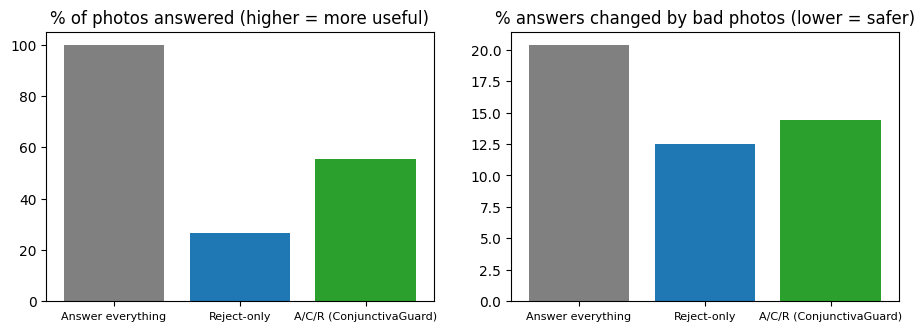

In [ ]:
clean_ans = res[res.damage == 'none'].set_index('file').p.map(lambda v: v >= THR)
res['clean_answer'] = res.file.map(clean_ans)

def summary(name, answered, p):
    a = res[answered]; ans = (p[answered] >= THR)
    return {'way of working': name, 'answered_%': 100 * answered.mean(),
            'different_from_clean_%': 100 * (ans.values != a.clean_answer.values).mean(),
            'accuracy_%': 100 * (ans.values == a.label.values.astype(bool)).mean(),
            'photos answered': int(answered.sum())}

comp = pd.DataFrame([
    summary('Answer everything', pd.Series(True, index=res.index), res.p),
    summary('Reject-only', res.decision == 'ACCEPT', res.p),
    summary('A/C/R (ConjunctivaGuard)', res.decision.isin(['ACCEPT', 'CORRECT']), res.p_final.fillna(res.p)),
]).round(1)
display(comp)

import matplotlib.pyplot as plt
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.bar(comp['way of working'], comp['answered_%'], color=['grey', 'tab:blue', 'tab:green']); a.set_title('% of photos answered (higher = more useful)')
b.bar(comp['way of working'], comp['different_from_clean_%'], color=['grey', 'tab:blue', 'tab:green']); b.set_title('% answers changed by bad photos (lower = safer)')
for ax in (a, b): ax.tick_params(axis='x', labelsize=8)
plt.show()

### Cell 7: did corrections keep the colour safe?
- **untouched ΔE00** (glare repair): colour change of the eyelid pixels the repair did **not** touch. Should be **0**: the repair must never change healthy tissue. This is your **ε** check.
- **ΔE00 to clean, before → after**: how far the photo's colour is from the true clean photo, before and after correcting. **After should be smaller.**

Expect: glare repairs get **closer** to the truth. The naive dark fix can move naturally darker eyelids (including some *clean* photos) **away** from their true colour: that is the colour-safety risk the full system's ε gate must stop.

In [ ]:
c = res[res.dE_after.notna()]
colour = c.groupby(['damage', 'level'])[['dE_untouched', 'dE_before', 'dE_after']].mean().round(2)
colour['tried'] = c.groupby(['damage', 'level']).size()
colour['passed re-check'] = c[c.decision == 'CORRECT'].groupby(['damage', 'level']).size()
display(colour.fillna('-'))

dE_untouched  dE_before  dE_after  tried  passed re-check
damage level                                                             
blur   mild                -       0.52     22.66      8                7
       moderate            -       0.85     22.73      8                6
       severe              -       1.61     23.66      6                6
dark   mild                -      11.93     13.74     30               29
       moderate            -      29.78      8.55     47               47
glare  mild              0.0       1.75      2.91     60               58
       moderate          0.0       5.57      3.80     61               57
none   clean               -       0.00     22.62      8                7

### Cell 8: the demo, three photos of the same child
What a user would see: the photo, the decision, the reason and the result (or no result).

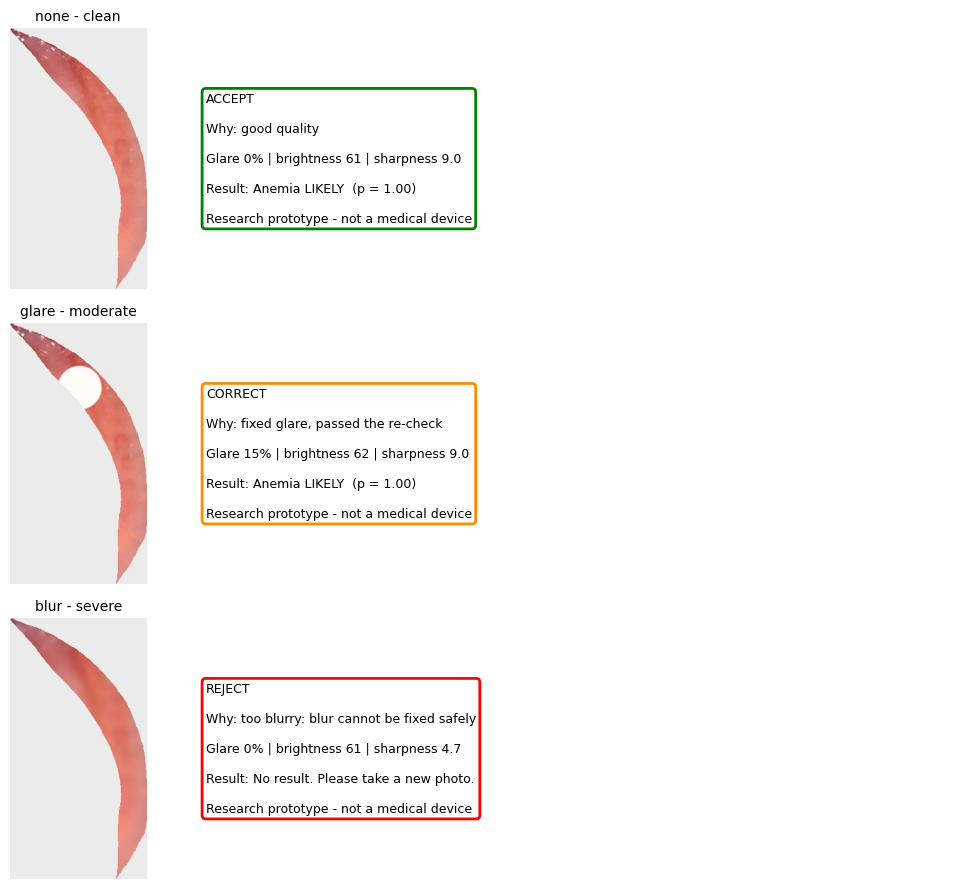

In [ ]:
def card(r, ax_img, ax_txt):
    rgb, tissue = load_rgba(r.path)
    show = np.full(rgb.shape, 235, np.uint8); show[tissue] = rgb[tissue]
    ax_img.imshow(show); ax_img.axis('off'); ax_img.set_title(f'{r.damage} - {r.level}', fontsize=10)
    colour = {'ACCEPT': 'green', 'CORRECT': 'darkorange', 'REJECT': 'red'}[r.decision]
    if r.decision == 'REJECT':
        result = 'No result. Please take a new photo.'
    else:
        result = ('Anemia LIKELY' if r.p_final >= THR else 'Anemia unlikely') + f'  (p = {r.p_final:.2f})'
    text = (f'{r.decision}\n\nWhy: {r.reason}\n\nGlare {100 * r.glare_share:.0f}% | brightness {r.brightness:.0f} | '
            f'sharpness {r.sharpness:.1f}\n\nResult: {result}\n\nResearch prototype - not a medical device')
    ax_txt.axis('off'); ax_txt.text(0, 0.5, text, fontsize=9, va='center', wrap=True,
                                    bbox=dict(boxstyle='round', fc='white', ec=colour, lw=2))

# one child whose clean photo is accepted, with a moderate-glare and a severe-blur version
def decision_of(x, d, l):
    return res[(res.file == x) & (res.damage == d) & (res.level == l)].decision.iloc[0]
files = list(res[res.damage == 'none'].file)
good = [x for x in files if decision_of(x, 'none', 'clean') == 'ACCEPT']
best = [x for x in good if decision_of(x, 'glare', 'moderate') == 'CORRECT']
f = (best or good or files)[0]
pick = [res[(res.file == f) & (res.damage == d) & (res.level == l)].iloc[0]
        for d, l in [('none', 'clean'), ('glare', 'moderate'), ('blur', 'severe')]]
fig, axes = plt.subplots(3, 2, figsize=(11, 9), gridspec_kw={'width_ratios': [1, 2]})
for r, (ai, at) in zip(pick, axes):
    card(r, ai, at)
plt.tight_layout(); plt.show()

### Cell 9: save the results

In [ ]:
keep = ['file', 'label', 'damage', 'level', 'p', 'decision', 'reason', 'p_final', 'glare_share', 'brightness',
        'sharpness', 'dE_untouched', 'dE_before', 'dE_after']
res[keep].to_csv(os.path.join(OUT, 'ACR_decisions.csv'), index=False)
comp.to_csv(os.path.join(OUT, 'ACR_comparison.csv'), index=False)
json.dump({k: round(v, 4) for k, v in T.items()} | {'TARGET_GRAY': round(TARGET_GRAY, 2), 'THR': THR},
          open(os.path.join(OUT, 'ACR_thresholds.json'), 'w'), indent=1)
print(comp.to_string(index=False))

          way of working  answered_%  different_from_clean_%  accuracy_%  photos answered
       Answer everything       100.0                    20.4        64.1              750
             Reject-only        26.7                    12.5        66.5              200
A/C/R (ConjunctivaGuard)        55.6                    14.4        62.4              417


### Part 6 done ✅
**Outputs to check:** the text output of **Cells 3, 4, 5, 6, 7 and 9**, and screenshots of the **Cell 6 graphs** and **Cell 8** (the demo).

**What this shows:** the full chain works end to end: data → eyelid → quality → decision → (fix → re-check) → result or no result. In the full system, the fixed rules become the **risk estimator (M6)** with the limit **τ**, and the colour check becomes the formal **ΔE00 ≤ ε** gate.

In [ ]:
c = res[res.dE_after.notna() & (res.damage == 'glare')].copy()
c['fix'] = c.reason.str.contains('dark').map({True: 'glare + dark fix', False: 'glare fix only'})
display(c.groupby(['level', 'fix'])[['dE_before', 'dE_after']].agg(['mean', 'count']).round(2))

dE_before       dE_after      
                               mean count     mean count
level    fix                                            
mild     glare + dark fix      2.58     8    20.39     8
         glare fix only        1.62    52     0.22    52
moderate glare + dark fix      8.03     9    20.85     9
         glare fix only        5.15    52     0.85    52